In [2]:
import pandas as pd

imputation_summary = pd.read_csv(
    "../05_Results/mean_median_summary.csv"
)

print("Rows:", len(imputation_summary))
print(imputation_summary.to_string(index=False))

Rows: 36
 Missing % Imputation               Model  Mean_Accuracy  Std_Accuracy  Mean_F1   Std_F1
         0       mean       Decision Tree       0.992727      0.000000 0.991870 0.000000
         0       mean Logistic Regression       0.985455      0.000000 0.983871 0.000000
         0       mean       Random Forest       0.996364      0.000000 0.995918 0.000000
         0     median       Decision Tree       0.992727      0.000000 0.991870 0.000000
         0     median Logistic Regression       0.985455      0.000000 0.983871 0.000000
         0     median       Random Forest       0.996364      0.000000 0.995918 0.000000
         5       mean       Decision Tree       0.986909      0.005515 0.985417 0.006021
         5       mean Logistic Regression       0.967273      0.005143 0.964451 0.005375
         5       mean       Random Forest       0.996364      0.000000 0.995918 0.000000
         5     median       Decision Tree       0.986909      0.006606 0.985417 0.007269
         5  

In [3]:
imputation_comparison = (
    imputation_summary
    .pivot_table(
        index=["Missing %", "Model"],
        columns="Imputation",
        values=["Mean_Accuracy", "Mean_F1"]
    )
    .reset_index()
)

print(imputation_comparison.to_string(index=False))

Missing %               Model Mean_Accuracy           Mean_F1         
                                       mean   median     mean   median
        0       Decision Tree      0.992727 0.992727 0.991870 0.991870
        0 Logistic Regression      0.985455 0.985455 0.983871 0.983871
        0       Random Forest      0.996364 0.996364 0.995918 0.995918
        5       Decision Tree      0.986909 0.986909 0.985417 0.985417
        5 Logistic Regression      0.967273 0.967273 0.964451 0.964451
        5       Random Forest      0.996364 0.996364 0.995918 0.995918
       10       Decision Tree      0.979636 0.981818 0.977056 0.979592
       10 Logistic Regression      0.954909 0.954182 0.950296 0.949448
       10       Random Forest      0.996364 0.996364 0.995918 0.995918
       20       Decision Tree      0.968727 0.969455 0.964628 0.965666
       20 Logistic Regression      0.946909 0.946182 0.941372 0.940523
       20       Random Forest      0.994182 0.994182 0.993509 0.993496
      

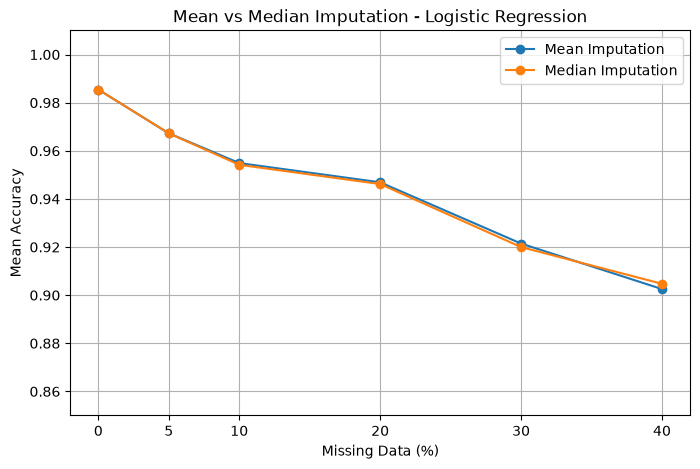

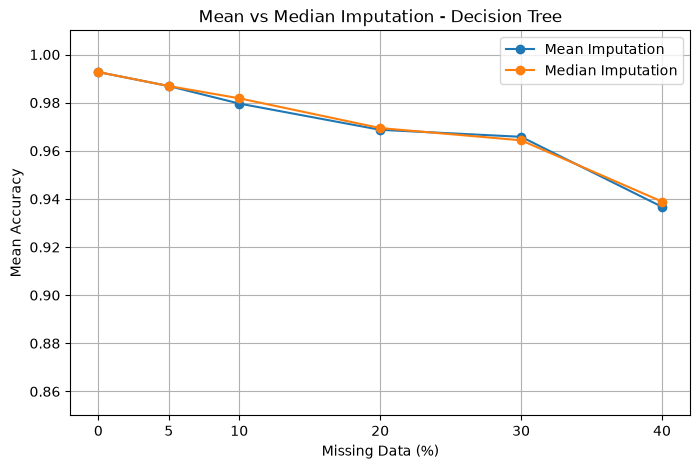

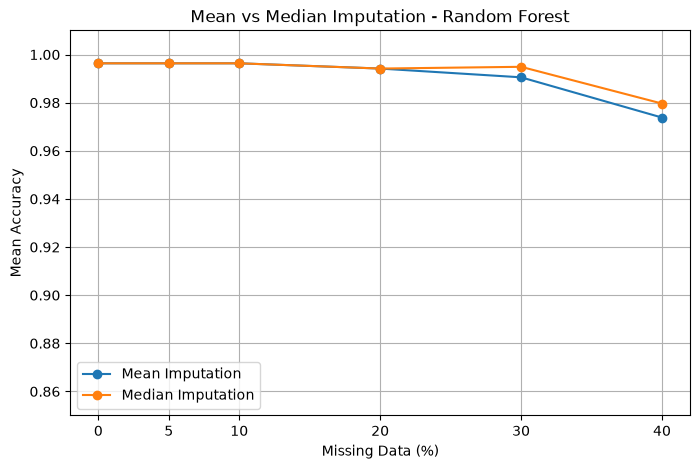

In [4]:
import matplotlib.pyplot as plt

models = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
]

for model in models:

    model_data = imputation_summary[
        imputation_summary["Model"] == model
    ]

    plt.figure(figsize=(8, 5))

    mean_data = model_data[
        model_data["Imputation"] == "mean"
    ]

    median_data = model_data[
        model_data["Imputation"] == "median"
    ]

    plt.plot(
        mean_data["Missing %"],
        mean_data["Mean_Accuracy"],
        marker="o",
        label="Mean Imputation"
    )

    plt.plot(
        median_data["Missing %"],
        median_data["Mean_Accuracy"],
        marker="o",
        label="Median Imputation"
    )

    plt.xlabel("Missing Data (%)")
    plt.ylabel("Mean Accuracy")
    plt.title(f"Mean vs Median Imputation - {model}")
    plt.xticks([0, 5, 10, 20, 30, 40])
    plt.ylim(0.85, 1.01)
    plt.legend()
    plt.grid(True)

    filename = (
        model.lower()
        .replace(" ", "_")
        .replace("-", "")
        + "_mean_vs_median_accuracy.png"
    )

    plt.savefig(
        f"../06_Figures/{filename}",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

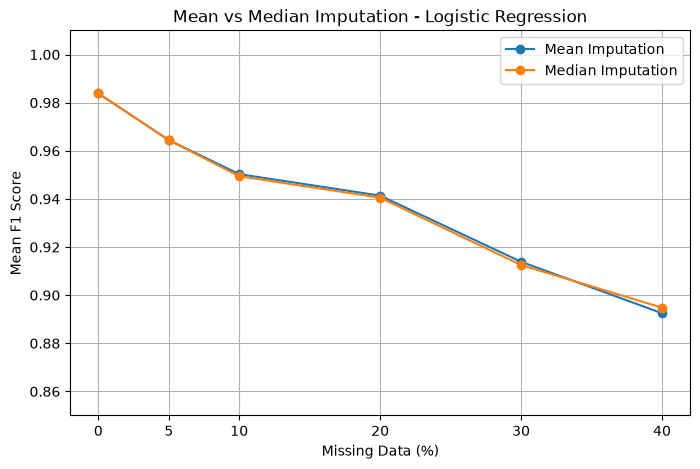

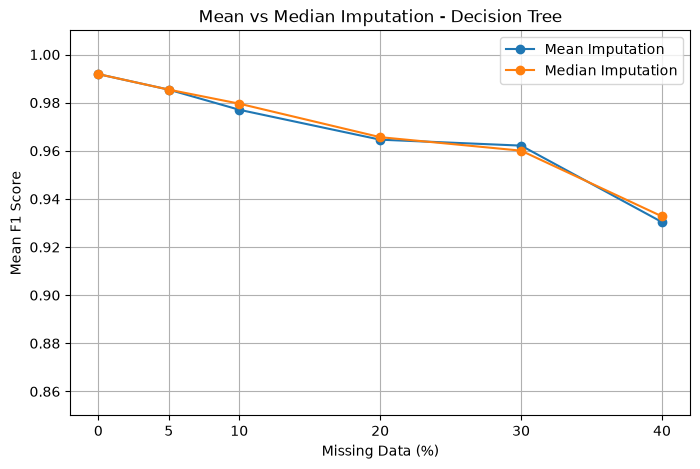

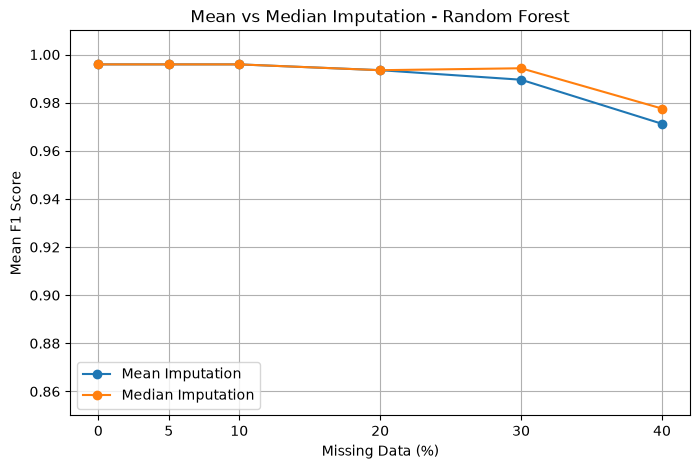

In [5]:
import matplotlib.pyplot as plt

models = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
]

for model in models:

    model_data = imputation_summary[
        imputation_summary["Model"] == model
    ]

    plt.figure(figsize=(8, 5))

    mean_data = model_data[
        model_data["Imputation"] == "mean"
    ]

    median_data = model_data[
        model_data["Imputation"] == "median"
    ]

    plt.plot(
        mean_data["Missing %"],
        mean_data["Mean_F1"],
        marker="o",
        label="Mean Imputation"
    )

    plt.plot(
        median_data["Missing %"],
        median_data["Mean_F1"],
        marker="o",
        label="Median Imputation"
    )

    plt.xlabel("Missing Data (%)")
    plt.ylabel("Mean F1 Score")
    plt.title(f"Mean vs Median Imputation - {model}")
    plt.xticks([0, 5, 10, 20, 30, 40])
    plt.ylim(0.85, 1.01)
    plt.legend()
    plt.grid(True)

    filename = (
        model.lower()
        .replace(" ", "_")
        .replace("-", "")
        + "_mean_vs_median_f1.png"
    )

    plt.savefig(
        f"../06_Figures/{filename}",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [6]:
final_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy_0%": [
        0.985455,
        0.992727,
        0.996364
    ],
    "Accuracy_40%": [
        0.904727,
        0.938909,
        0.979636
    ],
    "Drop_Points": [
        8.072727,
        5.381818,
        1.672727
    ]
})

print(final_results.to_string(index=False))

              Model  Accuracy_0%  Accuracy_40%  Drop_Points
Logistic Regression     0.985455      0.904727     8.072727
      Decision Tree     0.992727      0.938909     5.381818
      Random Forest     0.996364      0.979636     1.672727


In [7]:
final_results.to_csv(
    "../05_Results/final_model_comparison.csv",
    index=False
)

print("Final model comparison saved successfully.")

Final model comparison saved successfully.
